## PyTorch İş Akışı

Bir PyTorch uçtan uca iş akışı örneğini inceleyelim.

![images](images/01_a_pytorch_workflow.png)



In [1]:
what_were_covering = {
    1: "veri (hazırlama ve yükleme)",
    2: "model oluşturma",
    3: "modeli eğitme",
    4: "tahmin yapma ve modeli değerlendirme",
    5: "modeli kaydetme ve yükleme",
    6: "her şeyi bir araya getirme"
}
what_were_covering

{1: 'veri (hazırlama ve yükleme)',
 2: 'model oluşturma',
 3: 'modeli eğitme',
 4: 'tahmin yapma ve modeli değerlendirme',
 5: 'modeli kaydetme ve yükleme',
 6: 'her şeyi bir araya getirme'}

### torch.nn belgeleri

`torch.nn` = https://pytorch.org/docs/stable/nn.html


In [2]:
import torch 
from torch import nn
import matplotlib.pyplot as plt

# Check PyTorch version

torch.__version__

'2.3.1+cu118'

## 1. Veri (hazırlama ve yükleme)

Veri, makine öğrenmesinde neredeyse her şey olabilir...

* Excel tabloları  
* Her türden görseller  
* Videolar  
* Sesler  
* DNA  
* Metin  

Makine öğrenmesi iki parçadan oluşan bir oyundur:  
1. Veriyi sayısal bir temsile dönüştürmek.  
2. Bu sayısal temsildeki desenleri öğrenen bir model inşa etmek.  

Bunu göstermek için, doğrusal regresyon formülünü kullanarak bazı *bilinen* veriler oluşturacağız.

*Bilinen* **parametrelerle** düz bir çizgi yapmak için doğrusal regresyon formülünü kullanacağız.


In [3]:
# Bilinen parametreleri oluştur

weight = 0.7  # ağırlık
bias = 0.3    # bias (sapma)

# oluştur
start = 0     # başlangıç
end = 1       # bitiş
step = 0.02   # adım
x = torch.arange(start, end, step).unsqueeze(1)  # 0'dan 1'e kadar 0.02 adımlarla x değerleri (sütun vektörü haline getiriliyor)
y = weight * x + bias  # y = wx + b formülüyle hedef değerler hesaplanıyor

x[:10], y[:10]  # ilk 10 x ve y değerini göster


(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [4]:
len(x), len(y)

(50, 50)

### Veriyi eğitim ve test kümelerine ayırmak (genel olarak makine öğrenmesindeki en önemli kavramlardan biri)

Verilerimizle bir eğitim ve test kümesi oluşturalım.

In [5]:
# test train spilt ayirmasi
train_split = int(0.8 * len(x))
x_train, y_train = x[:train_split], y[:train_split]
x_test, y_test = x[train_split:], y[train_split:]
len(x_train), len(y_train), len(x_test), len(y_test)

(40, 40, 10, 10)

In [6]:
"""
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, shuffle=False)
len(x_train), len(y_train), len(x_test), len(y_test)
"""

'\nfrom sklearn.model_selection import train_test_split\nx_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, shuffle=False)\nlen(x_train), len(y_train), len(x_test), len(y_test)\n'

Verimizi daha iyi nasıl görselleştirebiliriz?

İşte burada veri kâşiflerinin mottosu devreye giriyor!


In [7]:
def plot_predictions(train_data=x_train,
                     train_labels=y_train,
                     test_data=x_test,
                     test_labels=y_test,
                     predictions=None,
                     labels=None,):
    plt.figure(figsize=(10, 7))  # Grafik boyutunu ayarla
    
    # Eğitim verilerini mavi ile çiz
    plt.scatter(train_data, train_labels, c="blue", s=6, label="Eğitim verisi")
    
    # Test verilerini yeşil ile çiz
    plt.scatter(test_data, test_labels, c="green", s=6, label="Test verisi")
    
    # Tahminler var mı?
    if predictions is not None:
        # Tahminleri kırmızı ile çiz
        plt.scatter(test_data, predictions, c="red", s=4, label="Tahminler")
    
    # Başlık varsa
    if labels is not None:
        labels = labels.title()
        plt.title(labels, fontweight="bold", fontsize="x-large")  # Grafik başlığı
    
    plt.legend(fontsize="large", loc="best")  # Açıklamaları göster


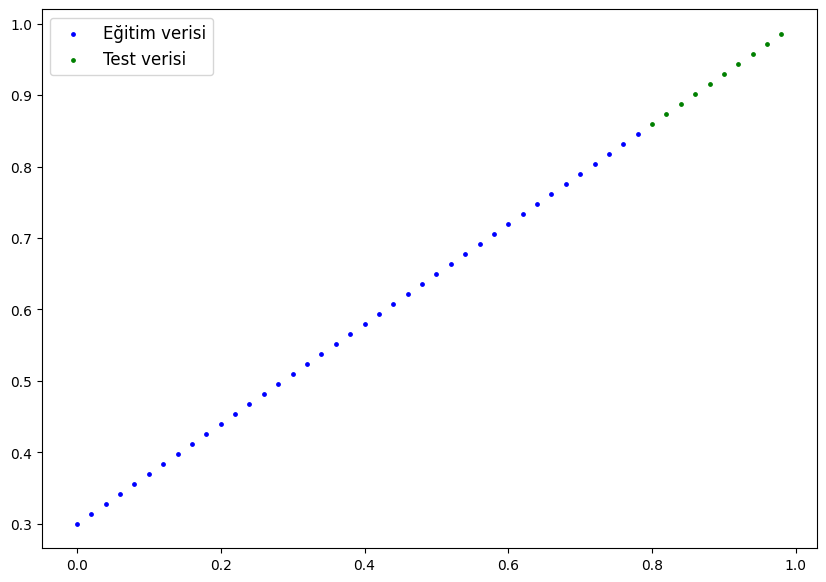

In [8]:
plot_predictions()

## 2. Model Oluşturma  
İlk PyTorch modelimiz

`Y = a + bx`

Modelimizin yaptığı şey:
* Rastgele değerlerle başlar (ağırlık ve bias)
* Eğitim verilerine bakar ve bu rastgele değerleri, ideal değerlere (veriyi oluşturmak için kullandığımız ağırlık ve bias'a) daha çok yaklaşacak şekilde ayarlar

Peki bunu nasıl yapar?
1. Gradyan inişi (Gradient Descent)  
2. Geri yayılım (Backpropagation)


In [9]:
# Doğrusal regresyon modeli oluşturma
from torch import nn

class LinearRegression(nn.Module):  # <- PyTorch'taki hemen her şey modül (module) içinde
    def __init__(self):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(1,  # Rastgele bir ağırlık oluştur
                                               requires_grad=True,
                                               dtype=torch.float))
        
        self.bias = nn.Parameter(torch.randn(1, requires_grad=True, dtype=torch.float))  # Rastgele bir bias (sapma) oluştur
        
    # Modeldeki hesaplamayı tanımlayan Forward metodu
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.weight * x + self.bias  # Bu, doğrusal regresyon formülüdür


### PyTorch model oluşturma temelleri

* **torch.nn** -> Hesaplama grafiklerinin tüm yapı taşlarını içerir (esas olarak belirli bir şekilde yürütülen bir dizi hesaplama).
* **torch.nn.Parameter** -> nn.Module ile kullanılabilen tensörleri saklar. Eğer `requires_grad=True` ise, gradyanlar (model parametrelerini gradyan inişi ile güncellemek için kullanılır) otomatik olarak hesaplanır, bu işleme genellikle "autograd" denir.
* **torch.nn.Module** -> Tüm sinir ağı modüllerinin temel sınıfıdır, sinir ağları için tüm yapı taşları alt sınıflardır. Eğer PyTorch'ta bir sinir ağı oluşturuyorsanız, modelleriniz nn.Module'den türemelidir. `forward()` metodunun implementasyonu gereklidir.
* **torch.optim** -> Çeşitli optimizasyon algoritmalarını içerir (bunlar model parametrelerine, nn.Parameter içinde saklanan verilere nasıl en iyi şekilde değiştirileceğini söyler, böylece gradyan inişi iyileştirilir ve kayıp azaltılır).
* **def forward()** -> Tüm nn.Module alt sınıfları, veriler üzerinde işlemi tanımlayan `forward()` metoduna ihtiyaç duyar (örneğin, yukarıdaki doğrusal regresyon formülü).


### PyTorch modelinin içeriğini kontrol etme
Şimdi bu temelleri hallettiğimize göre, oluşturduğumuz sınıf ile bir model örneği oluşturalım ve [`.parameters()`](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.parameters) metodunu kullanarak parametrelerini kontrol edelim.


In [10]:
# Rastgele bir tohum oluştur
torch.manual_seed(42)

# Modelin bir örneğini oluştur
model_0 = LinearRegression()

# Modelin parametrelerini listele
list(model_0.parameters())


[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [11]:
# İsimlendirilmiş parametreleri listele
model_0.state_dict()


OrderedDict([('weight', tensor([0.3367])), ('bias', tensor([0.1288]))])

### `torch.inference_mode()` kullanarak tahmin yapma

Modelimizin tahmin gücünü kontrol etmek için, `x_test` verilerine dayalı olarak `y_test`'i ne kadar iyi tahmin ettiğine bakalım.

Veriyi modelimizden geçirirken, bu veri `forward()` metodu aracılığıyla işlenecektir.


In [12]:
# Model ile tahmin yap
# torch.no_grad() ile:
    # y_pred = model_0(x_test)
with torch.inference_mode():
    y_pred = model_0(x_test)
y_pred


tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

In [13]:
y_test

tensor([[0.8600],
        [0.8740],
        [0.8880],
        [0.9020],
        [0.9160],
        [0.9300],
        [0.9440],
        [0.9580],
        [0.9720],
        [0.9860]])

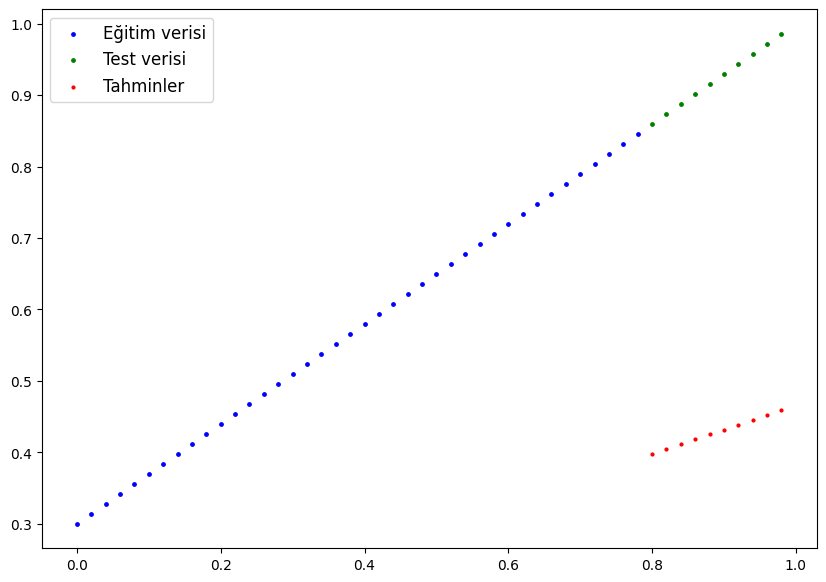

In [14]:
plot_predictions(predictions=y_pred)

### 3. Modeli Eğitmek

Eğitmenin tamamlayıcı fikri, bir modelin bazı *bilinmeyen* parametrelerden (bunlar rastgele olabilir) bazı *bilinen* parametrelere doğru ilerlemesidir.

Ya da, verinin kötü bir temsilinden, verinin daha iyi bir temsiline geçiş yapmak şeklinde ifade edebiliriz.

Modelinizin tahminlerinin ne kadar yanlış olduğunu ölçmenin bir yolu, kayıp fonksiyonlarını kullanmaktır.

Eğitim için ihtiyaç duyduğumuz şeyler:

* **Kayıp fonksiyonu:** Modelinizin tahminlerinin ideal çıktılara ne kadar yakın olduğunu ölçen bir fonksiyon, daha düşük değerler daha iyidir.
* **Optimizer (Optimizasyon algoritması):** Bir modelin kaybını dikkate alır ve model parametrelerini, kayıp fonksiyonunu iyileştirecek şekilde ayarlar.

Ve özellikle PyTorch için, şunlara ihtiyacımız vardır:

* Bir eğitim döngüsü
* Bir test döngüsü


In [15]:
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [16]:
model_0.state_dict()

OrderedDict([('weight', tensor([0.3367])), ('bias', tensor([0.1288]))])

### PyTorch'ta bir kayıp fonksiyonu ve optimizer (optimizasyon algoritması) oluşturma

Modelimizin kendi parametrelerini güncellemesi için, tarifimize birkaç şey daha eklememiz gerekecek.

Ve bu, bir **kayıp fonksiyonu** ve bir **optimizer** olacak.

Bunların rolleri şu şekildedir:

| Fonksiyon | Ne yapar? | PyTorch'ta nerede bulunur? | Yaygın değerler |
| ----- | ----- | ----- | ----- |
| **Kayıp fonksiyonu** | Modelinizin tahminlerinin (örneğin, `y_preds`) gerçeğe (örneğin, `y_test`) ne kadar yakın olduğunu ölçer. Daha düşük, daha iyidir. | PyTorch, [`torch.nn`](https://pytorch.org/docs/stable/nn.html#loss-functions) içinde pek çok yerleşik kayıp fonksiyonu sunar. | Regresyon problemleri için ortalama mutlak hata (MAE) ([`torch.nn.L1Loss()`](https://pytorch.org/docs/stable/generated/torch.nn.L1Loss.html)). İkili sınıflandırma problemleri için ikili çapraz entropi ([`torch.nn.BCELoss()`](https://pytorch.org/docs/stable/generated/torch.nn.BCELoss.html)). |
| **Optimizer** | Modelin parametrelerini, kaybı en aza indirecek şekilde nasıl güncellemesi gerektiğini belirtir. | Çeşitli optimizasyon fonksiyonu implementasyonlarını [`torch.optim`](https://pytorch.org/docs/stable/optim.html) içinde bulabilirsiniz. | Stokastik gradyan inişi (SGD) ([`torch.optim.SGD()`](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html#torch.optim.SGD)). Adam optimizerı ([`torch.optim.Adam()`](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html#torch.optim.Adam)). |

Modelimizi iyileştirmemize yardımcı olacak bir kayıp fonksiyonu ve bir optimizer oluşturalım.

Hangi tür problemin üzerinde çalıştığınıza bağlı olarak hangi kayıp fonksiyonunu ve hangi optimizer'ı kullanacağınız değişir.

Ancak, iyi sonuçlar verdiği bilinen bazı yaygın değerler vardır, örneğin SGD (stokastik gradyan inişi) veya Adam optimizer'ı. Ayrıca regresyon problemleri (bir sayı tahmin etmek) için MAE (ortalama mutlak hata) kayıp fonksiyonu ya da sınıflandırma problemleri (bir şeyi ya da başka bir şeyi tahmin etmek) için ikili çapraz entropi kayıp fonksiyonu kullanılabilir.

Bizim problemimizde, çünkü bir sayı tahmin ediyoruz, PyTorch'ta MAE (bu, `torch.nn.L1Loss()` altında yer alır) kayıp fonksiyonunu kullanacağız.

![MAE kaybının veri grafiğimizde nasıl göründüğü](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-mae-loss-annotated.png)
*Ortalama mutlak hata (MAE, PyTorch'ta: `torch.nn.L1Loss`) iki nokta (tahminler ve etiketler) arasındaki mutlak farkı ölçer ve ardından tüm örnekler üzerinden ortalama alır.*

Ve SGD kullanacağız, `torch.optim.SGD(params, lr)` şeklinde, burada:

* `params`, optimize etmek istediğiniz hedef model parametreleridir (örneğin, daha önce rastgele ayarladığımız `weight` ve `bias` değerleri).
* `lr` ise optimizer'ın parametreleri güncelleme hızıdır, daha yüksek bir değer optimizer'ın daha büyük güncellemeler yapmasına neden olur (bazen çok büyük olabilir ve optimizer başarısız olabilir), düşük bir değer ise daha küçük güncellemeler yapar (bazen çok küçük olabilir ve optimizer ideal değerlere ulaşmak için çok uzun sürebilir). Öğrenme oranı, bir **hiperparametre** olarak kabul edilir (çünkü bir makine öğrenimi mühendisi tarafından ayarlanır). Öğrenme oranı için yaygın başlangıç değerleri `0.01`, `0.001`, `0.0001`'dir, ancak bu değerler zamanla da ayarlanabilir (buna [öğrenme oranı zamanlaması](https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate) denir).

Vay, bu kadar şey var, şimdi bunu kodda görelim.


In [17]:
# Create the loss function
loss_fn = nn.L1Loss() # MAE loss is same as L1Loss

# Create the optimizer
optimizer = torch.optim.SGD(params=model_0.parameters(), # parameters of target model to optimize
                            lr=0.01) # learning rate (how much the optimizer should change parameters at each step, higher=more (less stable), lower=less (might take a long time))

### PyTorch Eğitim Döngüsü

Eğitim döngüsü için şu adımları oluşturacağız:

| Numara | Adım ismi                                                    | Ne yapar?                                                                                                                                                                                             | Kod örneği                        |
| ------ | ------------------------------------------------------------ | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | --------------------------------- |
| 1      | İleri geçiş (Forward pass)                                   | Model, tüm eğitim verilerinden bir kez geçer, `forward()` fonksiyonu hesaplamalarını yapar.                                                                                                           | `model(x_train)`                  |
| 2      | Kayıp fonksiyonunu hesapla                                   | Modelin çıktıları (tahminler), gerçek etiketlerle karşılaştırılır ve ne kadar yanlış oldukları değerlendirilir.                                                                                       | `loss = loss_fn(y_pred, y_train)` |
| 3      | Gradyanları sıfırla                                          | Optimizatörün gradyanları sıfırlanır (gradyanlar varsayılan olarak birikir), böylece belirli bir eğitim adımı için yeniden hesaplanabilir.                                                            | `optimizer.zero_grad()`           |
| 4      | Kayıp fonksiyonu üzerinde geri yayılım (backpropagation) yap | Kayıp fonksiyonunun her model parametresi ile ilişkili gradyanları hesaplar ve bu parametrelerin güncellenmesi gerekir (her parametrede `requires_grad=True` olmalıdır). Buna **geri yayılım** denir. | `loss.backward()`                 |
| 5      | Optimizatörü güncelle (**gradyan inişi**)                    | Kayıp gradyanlarına göre modelin parametrelerini (`requires_grad=True` olanları) günceller ve iyileştirir.                                                                                            | `optimizer.step()`                |

![pytorch eğitim döngüsü açıklamalı](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-training-loop-annotated.png)

> **Not:** Yukarıda verilenler, adımların nasıl sıralanabileceği veya açıklanabileceği konusunda bir örnektir. Deneyim kazandıkça, PyTorch eğitim döngülerini oldukça esnek bir şekilde oluşturabileceğinizi göreceksiniz.
>
> Ayrıca, adımların sıralanmasıyla ilgili olarak, yukarıda verilen sıralama iyi bir varsayılan sıralamadır, ancak bazı durumlarda biraz farklı sıralamalar görebilirsiniz. Bazı genel kurallar:
>
> * Kayıp fonksiyonunu hesapla (`loss = ...`) geri yayılım yapmadan **önce**.
> * Gradyanları sıfırla (`optimizer.zero_grad()`) kayıp fonksiyonunun gradyanlarını her model parametresiyle (`loss.backward()`) hesaplamadan **önce**.
> * Optimizatörü adım at (güncelle) (`optimizer.step()`) geri yayılımı yaptıktan (**loss.backward()**) sonra.

Arka planda geri yayılım ve gradyan inişi ile ilgili olanları anlamanıza yardımcı olacak kaynaklar için, ek müfredat bölümüne bakabilirsiniz.


### PyTorch Test Döngüsü

Modelimizi test ederken, tipik adımlar şunlardır:

| Numara | Adım ismi                                         | Ne yapar?                                                                                                                  | Kod örneği                       |
| ------ | ------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------- | -------------------------------- |
| 1      | İleri geçiş (Forward pass)                        | Model, tüm test verilerinden bir kez geçer, `forward()` fonksiyonu hesaplamalarını yapar.                                  | `model(x_test)`                  |
| 2      | Kayıp fonksiyonunu hesapla                        | Modelin çıktıları (tahminler), gerçek etiketlerle karşılaştırılır ve ne kadar yanlış oldukları değerlendirilir.            | `loss = loss_fn(y_pred, y_test)` |
| 3      | Değerlendirme metriklerini hesapla (isteğe bağlı) | Kayıp değerinin yanı sıra test seti üzerindeki doğruluk gibi diğer değerlendirme metriklerini hesaplamak isteyebilirsiniz. | Özel fonksiyonlar                |

Test döngüsünün, geri yayılım (`loss.backward()`) veya optimizatörü adım atma (`optimizer.step()`) işlemlerini içermediğine dikkat edin. Bunun nedeni, test sırasında modelin parametrelerinin değiştirilmemesidir, çünkü bunlar zaten hesaplanmıştır. Test sırasında yalnızca modelin ileri geçişinin çıktısı ile ilgileniyoruz.

![pytorch açıklamalı test döngüsü](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-testing-loop-annotated.png)

Yukarıdaki tüm adımları birleştirelim ve modelimizi 100 **epoch** (veri üzerinden ileri geçiş) boyunca eğitelim ve her 10 epoch'ta bir değerlendirelim.


In [18]:
torch.manual_seed(42)

# Epoch sayısını belirleyelim (modelin eğitim verisi üzerinden kaç kez geçeceği)
epochs = 150

# Kayıp değerlerini takip edebilmek için boş listeler oluşturalım
train_loss_values = []
test_loss_values = []
epoch_count = []

for epoch in range(epochs):
    ### Eğitim

    # Modeli eğitim moduna al (bu, modelin varsayılan durumudur)
    model_0.train()

    # 1. Eğitim verisi üzerinde ileri geçiş yap (forward() metodu ile)
    y_pred = model_0(x_train)

    # 2. Kayıp fonksiyonunu hesapla (modelin tahminleri ile gerçek değerler arasındaki fark)
    loss = loss_fn(y_pred, y_train)

    # 3. Optimizer'ın gradyanlarını sıfırla
    optimizer.zero_grad()

    # 4. Kayıp fonksiyonunu geriye yay (backward pass)
    loss.backward()

    # 5. Optimizer ile parametreleri güncelle
    optimizer.step()

    ### Test

    # Modeli değerlendirme moduna al
    model_0.eval()

    with torch.inference_mode():
        # 1. Test verisi üzerinde ileri geçiş yap
        test_pred = model_0(x_test)

        # 2. Test verisi üzerindeki kaybı hesapla
        test_loss = loss_fn(test_pred, y_test.type(torch.float)) # Tahminler torch.float veri tipinde geldiği için, karşılaştırmalar da aynı tipte yapılmalı

        # Her 10 epoch'ta bir durumu yazdır
        if epoch % 10 == 0:
            epoch_count.append(epoch)
            train_loss_values.append(loss.detach().numpy())
            test_loss_values.append(test_loss.detach().numpy())
            print(f"Epoch: {epoch} | MAE Train Loss: {loss} | MAE Test Loss: {test_loss} ")


Epoch: 0 | MAE Train Loss: 0.31288138031959534 | MAE Test Loss: 0.48106518387794495 
Epoch: 10 | MAE Train Loss: 0.1976713240146637 | MAE Test Loss: 0.3463551998138428 
Epoch: 20 | MAE Train Loss: 0.08908725529909134 | MAE Test Loss: 0.21729660034179688 
Epoch: 30 | MAE Train Loss: 0.053148526698350906 | MAE Test Loss: 0.14464017748832703 
Epoch: 40 | MAE Train Loss: 0.04543796554207802 | MAE Test Loss: 0.11360953003168106 
Epoch: 50 | MAE Train Loss: 0.04167863354086876 | MAE Test Loss: 0.09919948130846024 
Epoch: 60 | MAE Train Loss: 0.03818932920694351 | MAE Test Loss: 0.08886633068323135 
Epoch: 70 | MAE Train Loss: 0.03476089984178543 | MAE Test Loss: 0.0805937647819519 
Epoch: 80 | MAE Train Loss: 0.03132382780313492 | MAE Test Loss: 0.07232122868299484 
Epoch: 90 | MAE Train Loss: 0.02788739837706089 | MAE Test Loss: 0.06473556160926819 
Epoch: 100 | MAE Train Loss: 0.024458957836031914 | MAE Test Loss: 0.05646304413676262 
Epoch: 110 | MAE Train Loss: 0.021020207554101944 | MAE

Harika! Kayıpları (loss) her bir epoch için görselleştirebilmek için, matplotlib kullanarak eğitim ve test kayıplarını çizdirebiliriz. İşte nasıl yapabileceğiniz:

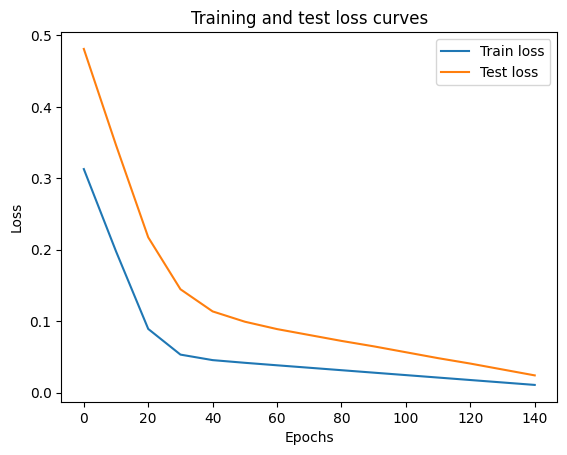

In [19]:
# Plot the loss curves
plt.plot(epoch_count, train_loss_values, label="Train loss")
plt.plot(epoch_count, test_loss_values, label="Test loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend();

Harika! **Kayıp eğrileri** zamanla kaybın azaldığını gösteriyor. Unutmayın, kayıp modelinizin ne kadar *yanlış* olduğunu ölçen bir değerdir, bu yüzden ne kadar düşükse o kadar iyidir.

Peki, neden kayıp azaldı?

İyi bir haber, kayıp fonksiyonumuz ve optimizasyonumuz sayesinde modelin iç parametreleri (`ağırlıklar` ve `bias`) verideki temel desenleri daha iyi yansıtacak şekilde güncellendi.

Modelimizin [`.state_dict()`](https://pytorch.org/tutorials/recipes/recipes/what_is_state_dict.html) fonksiyonunu inceleyerek, modelimizin ağırlıklar ve bias için belirlediğimiz orijinal değerlere ne kadar yakın olduğunu görelim.


In [20]:
# Find our model's learned parameters
print("The model learned the following values for weights and bias:")
print(model_0.state_dict())
print("\nAnd the original values for weights and bias are:")
print(f"weights: {weight}, bias: {bias}")

The model learned the following values for weights and bias:
OrderedDict({'weight': tensor([0.6638]), 'bias': tensor([0.3153])})

And the original values for weights and bias are:
weights: 0.7, bias: 0.3


Vay canına! Ne kadar havalı değil mi?

Modelimiz, `ağırlık` ve `bias` için belirlediğimiz orijinal değerlere oldukça yakın sonuçlar elde etti (ve muhtemelen daha uzun süre eğitim yapsaydık, daha da yakınlaşırdı).

> **Alıştırma:** Yukarıdaki `epochs` değerini 200'e değiştirin, kayıp eğrileri ve modelin ağırlıklar ve bias parametre değerlerinde ne gibi değişiklikler olduğunu gözlemleyin.

Muhtemelen onları *mükemmel* bir şekilde tahmin edemez (özellikle daha karmaşık veri setleri kullanıldığında) ama sorun değil, çoğu zaman yakın bir yaklaşım ile çok harika şeyler yapılabilir.

İşte makine öğrenmesi ve derin öğrenmesinin temel mantığı: **Verilerimizi tanımlayan bazı ideal değerler vardır** ve bunları elle bulmak yerine, **bir model eğiterek bunları programatik olarak bulabiliriz.**


## 4. Eğitimli Bir PyTorch Modeli ile Tahmin Yapmak (Çıkarım)

Bir model eğittiğinizde, büyük olasılıkla bununla tahmin yapmak isteyeceksiniz.

Bunun bir kısmını yukarıdaki eğitim ve test kodunda zaten görmüştük, eğitim/test döngüsünün dışında bunu yapmak için adımlar benzer olacaktır.

Bir PyTorch modeli ile tahmin yaparken (veya çıkarım yaparken) hatırlamanız gereken üç şey şunlardır:

1. Modeli değerlendirme moduna (evaluation mode) alınız (`model.eval()`).
2. Tahminleri çıkarım modu context manager'ı kullanarak yapınız (`with torch.inference_mode(): ...`).
3. Tüm tahminlerin aynı cihazda (örneğin, veri ve model sadece GPU'da veya sadece CPU'da) yapılması gerektiğini unutmayınız.

İlk iki madde, eğitim sırasında PyTorch'un arka planda kullandığı ve çıkarım için gerekli olmayan hesaplamaları ve ayarları kapatmayı sağlar (bu, daha hızlı hesaplama sonuçları elde etmenize olanak tanır). Üçüncü madde ise, cihazlar arası hata almamanızı sağlar.


In [21]:
# 1. Modeli değerlendirme moduna al
model_0.eval()

# 2. Çıkarım modu context manager'ını ayarla
with torch.inference_mode():
  # 3. Hesaplamaların model ve verinin aynı cihazda yapıldığından emin ol
  # Bu durumda, cihaz bağımsız bir kod henüz kurmadığımız için verilerimiz ve modelimiz
  # varsayılan olarak CPU'da.
  # model_0.to(device)
  # X_test = X_test.to(device)
  y_preds = model_0(x_test)
y_preds


tensor([[0.8464],
        [0.8596],
        [0.8729],
        [0.8862],
        [0.8995],
        [0.9127],
        [0.9260],
        [0.9393],
        [0.9526],
        [0.9659]])

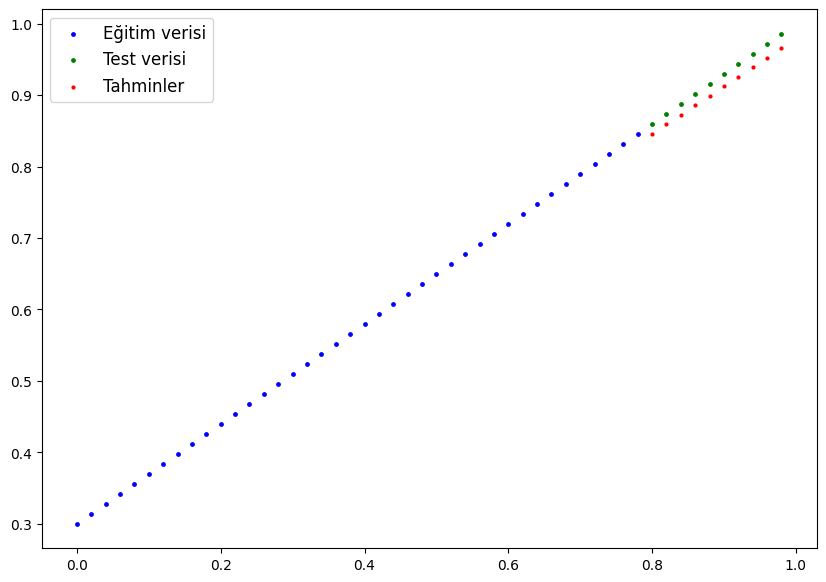

In [22]:
plot_predictions(predictions=y_preds)

## 5. Bir PyTorch Modelini Kaydetme ve Yükleme

Bir PyTorch modeli eğittiyseniz, muhtemelen onu kaydetmek ve bir yere aktarmak isteyeceksiniz.

Yani, modeli Google Colab'de ya da yerel makinenizde bir GPU ile eğitmiş olabilirsiniz ama şimdi bunu başkalarının kullanabileceği bir uygulamaya aktarmak istiyorsunuz.

Ya da belki bir modeldeki ilerlemenizi kaydetmek ve daha sonra geri dönüp yüklemek istiyorsunuz.

PyTorch'ta model kaydetme ve yükleme için bilmeniz gereken üç ana yöntem vardır (aşağıdakilerin tümü [PyTorch model kaydetme ve yükleme rehberinden](https://pytorch.org/tutorials/beginner/saving_loading_models.html#saving-loading-model-for-inference) alınmıştır):

| PyTorch yöntemi                                                                                                                                               | Ne yapar?                                                                                                                          |
| ------------------------------------------------------------------------------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------- |
| [`torch.save`](https://pytorch.org/docs/stable/torch.html?highlight=save#torch.save)                                                                          | Python’ın [`pickle`](https://docs.python.org/3/library/pickle.html) aracını kullanarak serileştirilmiş bir nesneyi diske kaydeder. |
| [`torch.load`](https://pytorch.org/docs/stable/torch.html?highlight=torch%20load#torch.load)                                                                  | `pickle` ile serileştirilmiş Python nesne dosyalarını (model, tensör veya sözlük gibi) belleğe yükler.                             |
| [`torch.nn.Module.load_state_dict`](https://pytorch.org/docs/stable/generated/torch.nn.Module.html?highlight=load_state_dict#torch.nn.Module.load_state_dict) | Kaydedilmiş bir `state_dict()` nesnesi ile bir modelin parametre sözlüğünü yükler.                                                 |

> **Not:** [Python’ın `pickle` dökümantasyonunda](https://docs.python.org/3/library/pickle.html) belirtildiği gibi, `pickle` modülü **güvenli değildir**. Yalnızca güvendiğiniz verileri yükleyin. PyTorch modelleri için de bu geçerlidir. Sadece güvendiğiniz kaynaklardan gelen modelleri kullanın.


### Bir PyTorch Modelinin `state_dict()`'ini Kaydetme

[Tavsiye edilen yöntem](https://pytorch.org/tutorials/beginner/saving_loading_models.html#saving-loading-model-for-inference), tahmin (inference) için bir modeli kaydetmenin ve yüklemenin yolu, modelin `state_dict()`'inin kaydedilip yüklenmesidir.

Birkaç adımda bunu nasıl yapacağımıza bakalım:

1. Python’un `pathlib` modülünü kullanarak `models` adında modellerin kaydedileceği bir dizin oluşturacağız.
2. Modelin kaydedileceği dosya yolunu oluşturacağız.
3. `torch.save(obj, f)` fonksiyonunu çağıracağız; burada `obj` hedef modelin `state_dict()`'i, `f` ise modelin kaydedileceği dosya adıdır.

> **Not:** PyTorch’ta kaydedilen modellerin ya da nesnelerin `.pt` veya `.pth` uzantılarıyla bitmesi yaygın bir kuraldır, örneğin `saved_model_01.pth`.


In [23]:
from pathlib import Path

# 1. Modeller için bir dizin oluştur
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Modelin kaydedileceği dosya yolunu oluştur
MODEL_NAME = "01_pytorch_workflow_model_0.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 3. Modelin state_dict (öğrenilen parametreler) bilgisini kaydet
print(f"Model şu konuma kaydediliyor: {MODEL_SAVE_PATH}")
torch.save(obj=model_0.state_dict(),  # Sadece state_dict() kaydedilir, bu sadece modelin öğrenilen parametreleridir
           f=MODEL_SAVE_PATH)


Model şu konuma kaydediliyor: models\01_pytorch_workflow_model_0.pth


### Kaydedilmiş bir PyTorch modelinin `state_dict()` verisini yükleme

Artık `models/01_pytorch_workflow_model_0.pth` konumunda kaydedilmiş bir model `state_dict()`'ine sahip olduğumuza göre, bunu `torch.nn.Module.load_state_dict(torch.load(f))` ile yükleyebiliriz; burada `f`, kaydedilmiş modelin `state_dict()` dosya yoludur.

**Neden `torch.nn.Module.load_state_dict()` içinde `torch.load()` çağrılıyor?**

Çünkü yalnızca modelin `state_dict()`'ini — yani öğrenilmiş parametrelerden oluşan sözlüğü — kaydettik, modelin *tamamını* değil. Bu yüzden önce `torch.load()` ile `state_dict()`'i yüklememiz ve ardından bunu, `nn.Module` sınıfından türetilmiş modelimizin yeni bir örneğine aktarmamız gerekiyor.

**Neden modelin tamamını kaydetmiyoruz?**

[Modelin tamamını kaydetmek](https://pytorch.org/tutorials/beginner/saving_loading_models.html#save-load-entire-model), sadece `state_dict()`'i kaydetmeye kıyasla daha sezgisel olabilir, ancak PyTorch belgelerinde şöyle uyarılıyor (*vurgu bana ait*):

> Bu yaklaşımın *(modelin tamamını kaydetmenin)* dezavantajı, serileştirilmiş verilerin, modelin kaydedildiği zamandaki belirli sınıflara ve tam dizin yapısına bağlı olmasıdır...
>
> Bu nedenle, modelinizi başka projelerde ya da yeniden yapılandırmalardan sonra kullanmaya çalıştığınızda kodunuz çeşitli şekillerde bozulabilir.

Bu yüzden biz, yalnızca `state_dict()` — yani model parametrelerinden oluşan esnek bir sözlük — kaydetme ve yükleme yöntemini kullanıyoruz.

Şimdi, `torch.nn.Module` sınıfından türetilmiş olan `LinearRegressionModel()` sınıfının yeni bir örneğini oluşturarak ve `load_state_dict()` metodunu kullanarak bunu test edelim.

In [24]:
# Modelimizin yeni bir örneğini oluştur (bu örnek rastgele ağırlıklarla başlatılacak)
loaded_model_0 = LinearRegression()

# Kaydedilmiş modelimizin state_dict'ini yükle (bu işlem, yeni model örneğini eğitilmiş ağırlıklarla güncelleyecek)
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))


<All keys matched successfully>

Harika! Görünüşe göre her şey uyumlu oldu.

Şimdi, yüklediğimiz model ile test verileri üzerinde tahmin yaparak (çıkarsama yaparak) modelimizi test edelim.

PyTorch modelleriyle çıkarsama yaparken hatırlamanız gereken kurallar nedir?

Eğer hatırlamıyorsanız, işte kısa bir hatırlatma:

<details>
    <summary>PyTorch çıkarsama kuralları</summary>
    <ol>
      <li> Modeli değerlendirme moduna ayarlayın (<code>model.eval()</code>). </li>
      <li> Çıkarsama yaparken, çıkarım modu context yöneticisini kullanarak tahmin yapın (<code>with torch.inference_mode(): ...</code>). </li>
      <li> Tüm tahminler aynı cihazda (örneğin veri ve model sadece GPU'da veya veri ve model sadece CPU'da) yapılmalıdır.</li>
    </ol> 
</details>

In [25]:
# 1. Yüklenen modeli değerlendirme moduna alın
loaded_model_0.eval()

# 2. Çıkarsama modu context yöneticisini kullanarak tahmin yapın
with torch.inference_mode():
    loaded_model_preds = loaded_model_0(x_test)  # Yüklenen model ile test verisi üzerinde ileri geçiş yaparak tahmin yapın


imdi, yüklenen model ile bazı tahminler yaptık, gelin bakalım bu tahminler önceki tahminlerle aynı mı?

In [26]:
# Önceki model tahminlerini yüklenen modelin tahminleriyle karşılaştır (bunlar aynı olmalı)
y_preds == loaded_model_preds


tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

## 6. Her şeyi bir araya getirme

Şimdiye kadar oldukça fazla yol katettik.

Ancak biraz pratik yaptıktan sonra, yukarıdaki adımları sanki sokakta dans eder gibi gerçekleştireceksiniz.

Pratik yapmaktan bahsetmişken, şimdiye kadar yaptıklarımızı bir araya getirelim.

Bu sefer kodumuzu cihazdan bağımsız (device agnostic) hale getireceğiz (yani bir GPU mevcutsa onu kullanacak, yoksa varsayılan olarak CPU'yu kullanacak).

Bu bölümde, daha önce yaptıklarımızı tekrar edeceğimiz için açıklamalar çok daha az olacak.

İhtiyacımız olan standart kütüphaneleri içeri aktararak başlayacağız.

> **Not:** Eğer Google Colab kullanıyorsanız, GPU ayarlamak için Runtime -> Change runtime type -> Hardware acceleration -> GPU yolunu takip edin. Bunu yaparsanız, Colab çalışma zamanı sıfırlanır ve kaydedilen değişkenler kaybolur.

In [27]:
# PyTorch ve matplotlib kütüphanelerini içeri aktar
import torch
from torch import nn  # nn, PyTorch'un sinir ağları için tüm yapı taşlarını içerir
import matplotlib.pyplot as plt

# PyTorch sürümünü kontrol et
torch.__version__

'2.3.1+cu118'

Şimdi kodumuzu cihazdan bağımsız hale getirelim. Eğer bir GPU (cuda) mevcutsa device="cuda" olarak ayarlayacağız, yoksa varsayılan olarak device="cpu" olacak.

In [28]:
# Cihazdan bağımsız kodu ayarla
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Kullanılan cihaz: {device}")


Kullanılan cihaz: cuda


Eğer bir GPU'ya erişiminiz varsa, yukarıdaki kod şu çıktıyı vermeliydi:

```
Kullanılan cihaz: cuda
```

Aksi takdirde, aşağıdaki hesaplamalar için CPU kullanılacaktır. Bu, küçük veri setimiz için sorun değil, ancak daha büyük veri setlerinde daha uzun sürebilir.

### 6.1 Veri

Hadi, tıpkı daha önce yaptığımız gibi bazı veriler oluşturalım.

İlk olarak, bazı `weight` ve `bias` değerlerini sabit olarak belirleyeceğiz.

Sonra, 0 ile 1 arasında bir sayı aralığı oluşturacağız, bunlar bizim `X` değerlerimiz olacak.

Son olarak, `X` değerlerini ve `weight` ile `bias` değerlerini kullanarak, doğrusal regresyon formülüyle (`y = weight * X + bias`) `y`'yi oluşturacağız.

In [29]:
# Ağırlık ve bias oluştur
weight = 0.7
bias = 0.3

# Aralık değerleri oluştur
start = 0
end = 1
step = 0.02

# X ve y (özellikler ve etiketler) oluştur
X = torch.arange(start, end, step).unsqueeze(dim=1)  # unsqueeze kullanılmazsa, daha sonra hata alırsınız (doğrusal katmanlarda şekil hataları)
y = weight * X + bias
X[:10], y[:10]


(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))


Harika!

Şimdi bazı verilerimiz var, bunları eğitim ve test setlerine bölelim.

Veriyi %80 eğitim ve %20 test olacak şekilde böleceğiz.



In [30]:
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

Verileri Gorsellestirelim

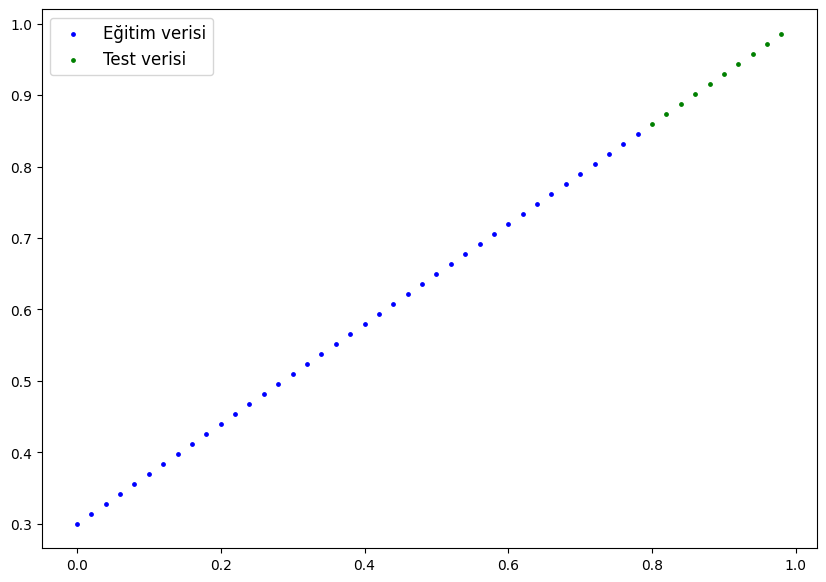

In [31]:
plot_predictions(X_train, y_train, X_test, y_test)

### 6.2 PyTorch Doğrusal Modeli Kurma

Bazı verilerimiz var, şimdi bir model yapma zamanı.

Öncekilerle aynı tarzda bir model oluşturacağız, ancak bu sefer modelimizin ağırlık ve bias parametrelerini `nn.Parameter()` ile manuel olarak tanımlamak yerine, [`nn.Linear(in_features, out_features)`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) kullanacağız.

`in_features`, giriş verinizin boyut sayısını, `out_features` ise çıktısını almak istediğiniz boyut sayısını belirtir.

Bizim durumumuzda, her etiket (`y`) için verimizde `1` giriş özelliği (`X`) olduğundan her ikisi de `1`'dir.

![nn.Parameter ile Doğrusal Regresyon Modeli ve nn.Linear ile Doğrusal Regresyon Modeli karşılaştırması](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-linear-regression-model-with-nn-Parameter-and-nn-Linear-compared.png)
*`nn.Parameter` kullanarak doğrusal regresyon modeli oluşturma ile `nn.Linear` kullanarak doğrusal regresyon modeli oluşturma karşılaştırması. `torch.nn` modülünün önceden yapılmış birçok hesaplaması ve popüler, kullanışlı sinir ağı katmanları da dahil olmak üzere daha birçok örnek bulunmaktadır.*

In [32]:
# Modelimizi oluşturmak için nn.Module'den subclass (alt sınıf) oluştur
class LinearRegressionModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        # Model parametrelerini oluşturmak için nn.Linear() kullan
        self.linear_layer = nn.Linear(in_features=1, 
                                      out_features=1)
    
    # İleri yönlü hesaplamayı tanımla (giriş verisi x, nn.Linear() üzerinden akar)
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear_layer(x)

# Modeli oluştururken manuel seed ayarla (bu her zaman gerekli değildir ama gösterim amaçlı kullanılmıştır, denemek için bunu yoruma alıp ne olduğunu görebilirsiniz)
torch.manual_seed(42)
model_1 = LinearRegressionModelV2()
model_1, model_1.state_dict()


(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

`model_1.state_dict()` çıktısını fark edin, `nn.Linear()` katmanı bizim için rastgele bir `weight` ve `bias` parametresi oluşturdu.

Şimdi modelimizi GPU'ya (eğer mevcutsa) taşıyalım.

PyTorch nesnelerimizin bulunduğu cihazı `.to(device)` kullanarak değiştirebiliriz.

İlk olarak modelimizin mevcut cihazını kontrol edelim.

In [33]:
next(model_1.parameters()).device

device(type='cpu')

Harika, modelin varsayılan olarak CPU'da olduğu görünüyor.

Şimdi bunu GPU'ya (eğer mevcutsa) taşıyalım.

In [34]:
# Modeli GPU'ya taşı, eğer mevcutsa; değilse CPU'ya dönecek
model_1.to(device)  # device değişkeni yukarıda "cuda" olarak ayarlandı, eğer mevcutsa; değilse "cpu" olarak ayarlandı
next(model_1.parameters()).device


device(type='cuda', index=0)

### 6.3 Training

Şimdi eğitim ve test döngüsünü kurma zamanı.

İlk olarak bir kayıp fonksiyonuna ve bir optimizere ihtiyacımız olacak.

Daha önce kullandığımız aynı fonksiyonları kullanalım, yani `nn.L1Loss()` ve `torch.optim.SGD()`.

Yeni modelin parametrelerini (`model.parameters()`) optimizere geçmemiz gerekecek, böylece eğitim sırasında bunları ayarlayabilir.

Önceki örnekte `0.01` öğrenme oranı iyi çalışmıştı, bu yüzden tekrar bunu kullanacağız.

In [35]:

loss_fn = nn.L1Loss()

optimizer = torch.optim.SGD(params=model_1.parameters(), # optimize newly created model's parameters
                            lr=0.01)

Harika, kayıp fonksiyonu ve optimizör hazır, şimdi eğitim ve test döngüsü kullanarak modelimizi eğitelim ve değerlendirelim.

Bu adımda önceki eğitim döngüsünden tek farkımız, veriyi hedef `device`'a (cihaz) koymamız olacak.

Daha önce modelimizi `model_1.to(device)` ile hedef `device`'a koymuştuk.

Aynı şeyi verilerle de yapabiliriz.

Böylece model GPU'daysa, veriler de GPU'ya (veya tersi) taşınmış olur.

Bu sefer bir adım daha ileri gidelim ve `epochs=1000` olarak ayarlayalım.

Eğer PyTorch eğitim döngüsü adımlarını hatırlamanıza ihtiyaç varsa, aşağıda bulabilirsiniz.

<details>
    <summary>PyTorch eğitim döngüsü adımları</summary>
    <ol>
        <li><b>İleri geçiş (Forward pass)</b> - Model, tüm eğitim verilerinden bir kez geçer, 
            <code>forward()</code> fonksiyonundaki hesaplamaları gerçekleştirir 
            (<code>model(x_train)</code>).
        </li>
        <li><b>Kayıp hesaplama (Calculate the loss)</b> - Modelin çıktıları (tahminler), gerçek değerlerle karşılaştırılır ve
            ne kadar yanlış oldukları değerlendirilir (<code>loss = loss_fn(y_pred, y_train)</code>).
        </li>
        <li><b>Gradyanları sıfırlama (Zero gradients)</b> - Optimizörün gradyanları sıfırlanır (varsayılan olarak birikirler),
            böylece belirli eğitim adımı için yeniden hesaplanabilirler (<code>optimizer.zero_grad()</code>).
        </li>
        <li><b>Kayıp üzerinde geri yayılım yapma (Perform backpropagation on the loss)</b> - Kayıp fonksiyonunun gradyanı,
            güncellenmesi gereken her model parametresi için hesaplanır (her parametre
            <code>requires_grad=True</code> olmalıdır). Buna <b>geri yayılım (backpropagation)</b> denir, bu yüzden "backwards" 
            (<code>loss.backward()</code>).
        </li>
        <li><b>Optimizör adımını atma (Step the optimizer)</b> - Parametreler, kayıp gradyanlarına göre güncellenir 
            (<code>optimizer.step()</code>).
        </li>
    </ol>
</details>

In [36]:
torch.manual_seed(42)

# Epok sayısını belirleyelim
epoch_sayisi = 1000

# Veriyi mevcut cihaza aktaralım
# Bu adım olmadan hata oluşacaktır (model ve veriler aynı cihazda olmalı)
X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

for epoch in range(epoch_sayisi):
    ### Eğitim
    model_1.train()  # Eğitim modunu aktif ediyoruz (model zaten yapım sırasında eğitim modunda)

    # 1. İleri geçiş (forward pass)
    y_pred = model_1(X_train)

    # 2. Kayıp hesaplama
    kayip = loss_fn(y_pred, y_train)

    # 3. Optimizörün gradyanlarını sıfırlama
    optimizer.zero_grad()

    # 4. Kayıp geri yayılımı
    kayip.backward()

    # 5. Optimizörü adım atmaya yönlendirme (ağırlıkları güncelleme)
    optimizer.step()

    ### Test
    model_1.eval()  # Test için modelin değerlendirme moduna geçmesi gerektiğini belirtiriz (sadece tahmin yapacak)

    # 1. İleri geçiş (forward pass)
    with torch.inference_mode():  # Gradyan hesaplamadan tahmin yapılacak
        test_pred = model_1(X_test)

        # 2. Kayıp hesaplama
        test_kayip = loss_fn(test_pred, y_test)

    if epoch % 100 == 0:
        print(f"Epok: {epoch} | Eğitim kaybı: {kayip} | Test kaybı: {test_kayip}")


Epok: 0 | Eğitim kaybı: 0.5551779866218567 | Test kaybı: 0.5739762187004089
Epok: 100 | Eğitim kaybı: 0.006215683650225401 | Test kaybı: 0.014086711220443249
Epok: 200 | Eğitim kaybı: 0.0012645035749301314 | Test kaybı: 0.013801801018416882
Epok: 300 | Eğitim kaybı: 0.0012645035749301314 | Test kaybı: 0.013801801018416882
Epok: 400 | Eğitim kaybı: 0.0012645035749301314 | Test kaybı: 0.013801801018416882
Epok: 500 | Eğitim kaybı: 0.0012645035749301314 | Test kaybı: 0.013801801018416882
Epok: 600 | Eğitim kaybı: 0.0012645035749301314 | Test kaybı: 0.013801801018416882
Epok: 700 | Eğitim kaybı: 0.0012645035749301314 | Test kaybı: 0.013801801018416882
Epok: 800 | Eğitim kaybı: 0.0012645035749301314 | Test kaybı: 0.013801801018416882
Epok: 900 | Eğitim kaybı: 0.0012645035749301314 | Test kaybı: 0.013801801018416882


In [37]:
from pprint import pprint  # pprint = güzel yazdırma, daha iyi biçimlendirilmiş çıktı sağlar (detaylı bilgi için: https://docs.python.org/3/library/pprint.html)

# Modelin öğrendiği ağırlık ve bias değerlerini yazdıralım
print("Model, aşağıdaki ağırlık ve bias değerlerini öğrendi:")
pprint(model_1.state_dict())

# Orijinal ağırlık ve bias değerlerini yazdıralım
print("\nVe orijinal ağırlık ve bias değerleri şunlardır:")
print(f"ağırlıklar: {weight}, bias: {bias}")


Model, aşağıdaki ağırlık ve bias değerlerini öğrendi:
OrderedDict([('linear_layer.weight', tensor([[0.6968]], device='cuda:0')),
             ('linear_layer.bias', tensor([0.3025], device='cuda:0'))])

Ve orijinal ağırlık ve bias değerleri şunlardır:
ağırlıklar: 0.7, bias: 0.3


### 6.4 Tahmin Yapma

Şimdi eğitimli bir modelimiz var, gelin modelin değerlendirme modunu açalım ve bazı tahminler yapalım.


In [38]:
# Modeli değerlendirme moduna alma
model_1.eval()

# Test verisi üzerinde tahminler yapma
with torch.inference_mode():
    y_preds = model_1(X_test)
y_preds


tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]], device='cuda:0')

Eğer tahminler yaparken veriler GPU üzerinde ise, yukarıdaki çıktıda sonlarda `device='cuda:0'` ifadesini görebilirsiniz. Bu, verilerin CUDA cihazı 0'da (sisteminize erişimi olan ilk GPU) olduğunu gösterir; eğer gelecekte birden fazla GPU kullanırsanız, bu numara daha yüksek olabilir.

Şimdi, modelimizin tahminlerini görselleştirelim.

> **Not:** Pandas, matplotlib ve NumPy gibi birçok veri bilimi kütüphanesi, GPU üzerinde depolanan verilerle çalışamaz. Bu nedenle, bu kütüphanelerden birinin fonksiyonunu, CPU üzerinde depolanmayan tensör verileriyle kullanmaya çalışırken bazı sorunlarla karşılaşabilirsiniz. Bunu çözmek için hedef tensörünüz üzerinde [`.cpu()`](https://pytorch.org/docs/stable/generated/torch.Tensor.cpu.html) fonksiyonunu çağırarak, hedef tensörünüzün CPU'da bir kopyasını alabilirsiniz.


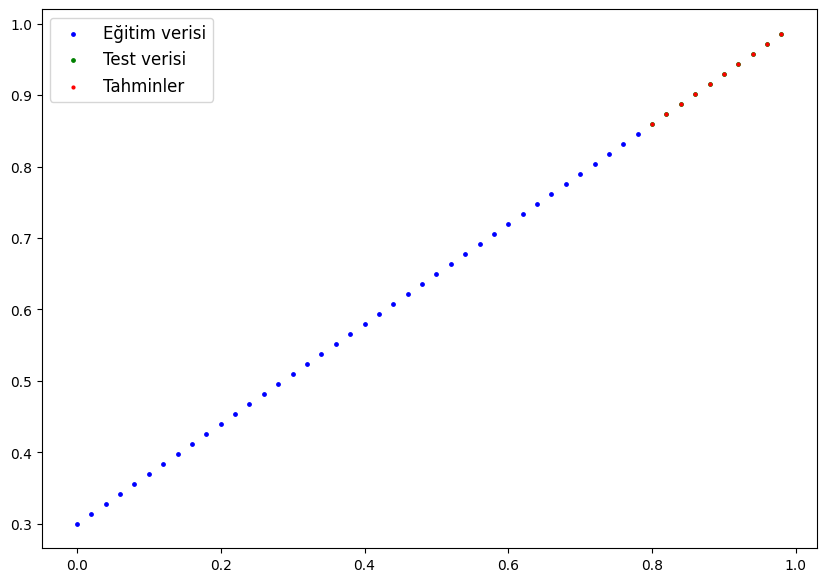

In [39]:
plot_predictions(predictions=y_preds.cpu())

### 6.5 Bir Modeli Kaydetme ve Yükleme

Modelimizin tahminlerinden memnun kaldık, şimdi modeli dosyaya kaydedelim, böylece ilerleyen zamanlarda tekrar kullanılabilir.


In [40]:
from pathlib import Path

# 1. Modeller dizini oluştur
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Model kaydetme yolu oluştur
MODEL_NAME = "01_pytorch_workflow_model_1.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 3. Modelin state dict'ini kaydet
print(f"Model şu yere kaydediliyor: {MODEL_SAVE_PATH}")
torch.save(obj=model_1.state_dict(), # sadece state_dict() kaydedildiğinde modelin öğrendiği parametreler kaydedilir
           f=MODEL_SAVE_PATH)


Model şu yere kaydediliyor: models\01_pytorch_workflow_model_1.pth


Ve her şeyin doğru şekilde çalıştığından emin olmak için, kaydettiğimiz modeli tekrar yükleyelim.

Yapacağımız işlemler şunlar olacak:

* `LinearRegressionModelV2()` sınıfından yeni bir model örneği oluşturacağız.
* `torch.nn.Module.load_state_dict()` kullanarak modelin state dict'ini yükleyeceğiz.
* Modelin yeni örneğini hedef cihaza (GPU veya CPU) göndereceğiz, böylece kodumuz cihaz bağımsız olur.


In [41]:
# LinearRegressionModelV2 sınıfından yeni bir örnek oluştur
loaded_model_1 = LinearRegressionModelV2()

# Modelin state dict'ini yükle
loaded_model_1.load_state_dict(torch.load(MODEL_SAVE_PATH))

# Modeli hedef cihaza gönder (verileriniz GPU'da ise, tahminler yapabilmesi için model de GPU'da olmalı)
loaded_model_1.to(device)

print(f"Yüklenen model:\n{loaded_model_1}")
print(f"Modelin cihazı:\n{next(loaded_model_1.parameters()).device}")


Yüklenen model:
LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)
Modelin cihazı:
cuda:0


Şimdi, kaydedilen modeli değerlendirerek, tahminlerinin kaydetmeden önce yapılan tahminlerle uyumlu olup olmadığını kontrol edebiliriz. Bunun için modelin test verisi üzerinde tahminler yaparak sonuçları karşılaştıracağız.

İşte adımlar:

1. Yüklenen model üzerinde test verisiyle tahminler yapalım.
2. Önceden kaydedilen tahminlerle karşılaştırarak doğruluğu kontrol edelim.


In [42]:
loaded_model_1.eval()
with torch.inference_mode():
    loaded_model_1_preds = loaded_model_1(X_test)
y_preds == loaded_model_1_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]], device='cuda:0')

Her şey tam olarak yerli yerine oturdu! Harika!

Gerçekten uzun bir yol kat ettik. Artık PyTorch'ta ilk iki sinir ağı modelinizi oluşturup eğittiniz!

Şimdi becerilerinizi pekiştirme zamanı. Bolca pratik yaparak bu yeteneklerinizi daha da geliştirebilirsiniz. Yeni projelerde başarılar dilerim!
